In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import zipfile

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
from google.colab import files

uploaded = files.upload()

zip_files = [f for f in uploaded if f.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload the Kaggle ZIP file.")

extract_folder = "/content/employee_attrition_data"
os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_files[0], "r") as z:
    z.extractall(extract_folder)

print("ZIP file extracted successfully!")

Saving archive (3).zip to archive (3) (3).zip
ZIP file extracted successfully!


In [12]:
csv_files = glob.glob(
    extract_folder + "/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError("No CSV file found inside the ZIP.")

matching = [
    f for f in csv_files
    if "attrition" in os.path.basename(f).lower()
]

csv_path = matching[0] if matching else csv_files[0]

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
display(df.head())

CSV files found: ['/content/employee_attrition_data/WA_Fn-UseC_-HR-Employee-Attrition.csv']
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [13]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


In [14]:
cleaned_df = df.copy()

cleaned_df.columns = (
    cleaned_df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Duplicate rows:", cleaned_df.duplicated().sum())

cleaned_df = cleaned_df.drop_duplicates().copy()

for col in cleaned_df.select_dtypes(include=["object", "string"]):
    cleaned_df[col] = cleaned_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Cleaning completed.")
print("New shape:", cleaned_df.shape)

Duplicate rows: 0
Cleaning completed.
New shape: (1470, 35)


In [15]:
print("Missing values:")
display(cleaned_df.isnull().sum().sort_values(ascending=False))

if "employeenumber" in cleaned_df.columns:
    print(
        "Duplicate employee IDs:",
        cleaned_df["employeenumber"].duplicated().sum()
    )

Missing values:


,0
age,0
attrition,0
businesstravel,0
dailyrate,0
department,0
distancefromhome,0
education,0
educationfield,0
employeecount,0
employeenumber,0


Duplicate employee IDs: 0


In [16]:
print(cleaned_df["attrition"].value_counts(dropna=False))

cleaned_df["attrition_flag"] = (
    cleaned_df["attrition"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

display(cleaned_df[["attrition", "attrition_flag"]].head())

attrition
No     1233
Yes     237
Name: count, dtype: int64


,attrition,attrition_flag
0,Yes,1
1,No,0
2,Yes,1
3,No,0
4,No,0


,Department,Employees,Leavers,Attrition_Rate
0,Human Resources,63,12,19.047619
1,Research & Development,961,133,13.839750
2,Sales,446,92,20.627803


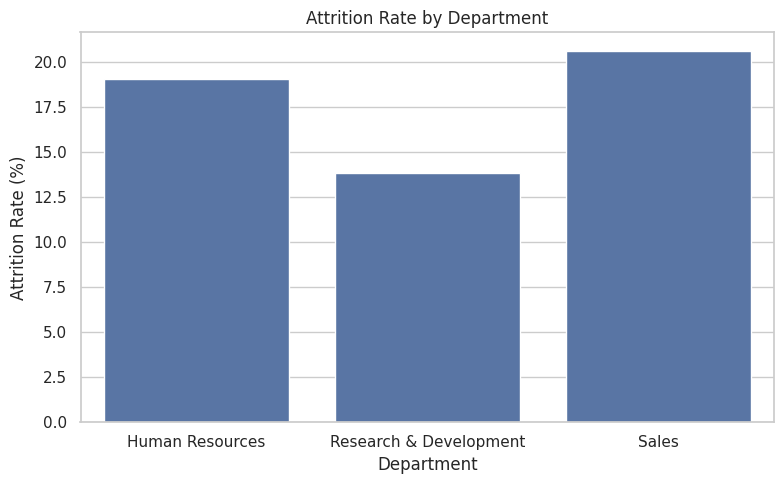

In [17]:
department_analysis = (
    cleaned_df.groupby("department")["attrition_flag"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

department_analysis.columns = [
    "Department", "Employees", "Leavers", "Attrition_Rate"
]

department_analysis["Attrition_Rate"] *= 100

display(department_analysis)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=department_analysis,
    x="Department",
    y="Attrition_Rate"
)
plt.title("Attrition Rate by Department")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

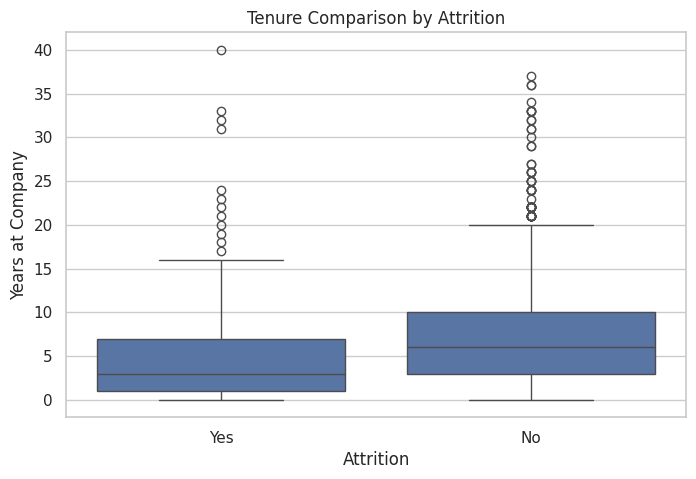

,count,mean,median
attrition,,,
No,1233,7.369019,6.0
Yes,237,5.130802,3.0


In [21]:



plt.figure(figsize=(8, 5))

sns.boxplot(data=cleaned_df, x="attrition", y="yearsatcompany")

plt.title("Tenure Comparison by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")
plt.show()

# Display summary
display(
    cleaned_df.groupby("attrition")["yearsatcompany"]
    .agg(["count", "mean", "median"])
)


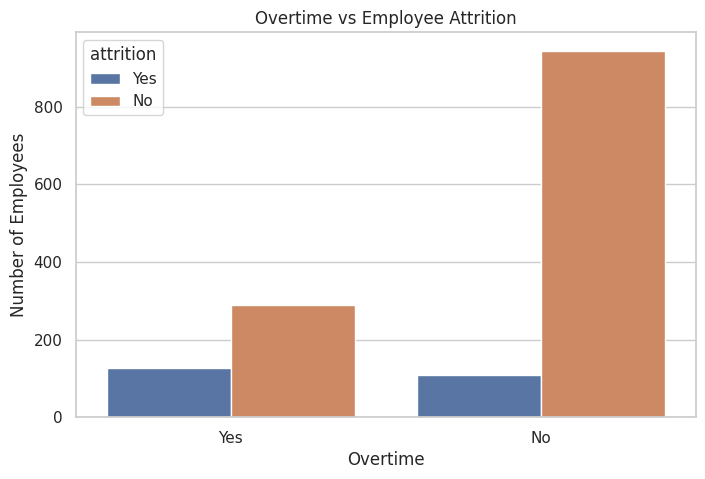

attrition,No,Yes,All
overtime,,,
No,944,110,1054
Yes,289,127,416
All,1233,237,1470


In [22]:

# Step 10: Analyze overtime and attrition

plt.figure(figsize=(8, 5))

sns.countplot(data=cleaned_df, x="overtime", hue="attrition")

plt.title("Overtime vs Employee Attrition")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")
plt.show()

# Display summary
display(pd.crosstab(
    cleaned_df["overtime"],
    cleaned_df["attrition"],
    margins=True
))


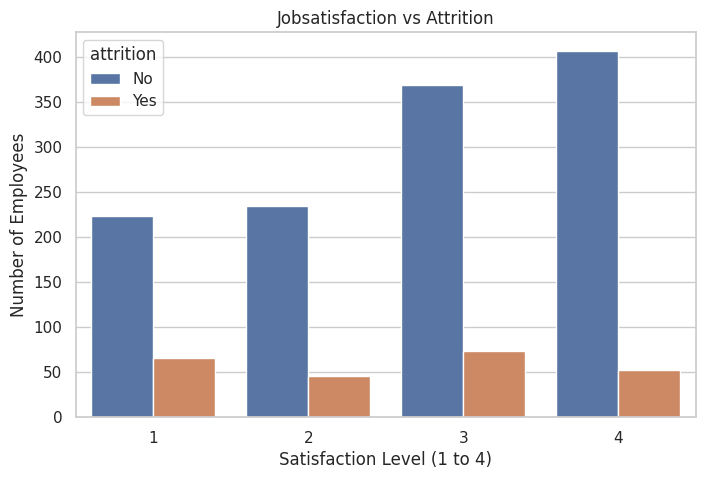

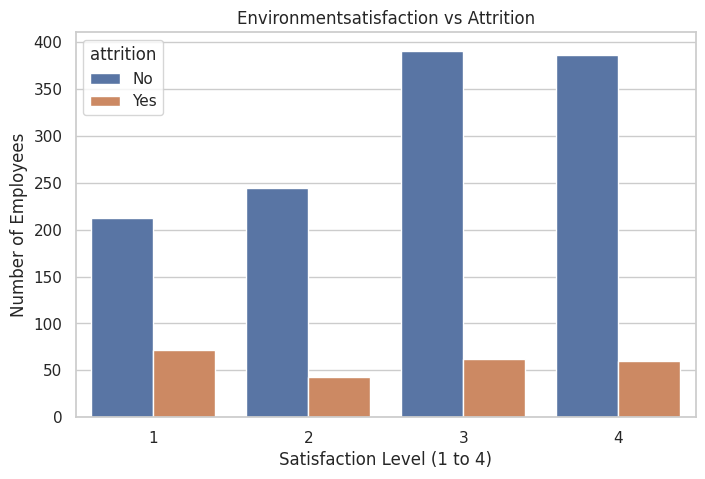

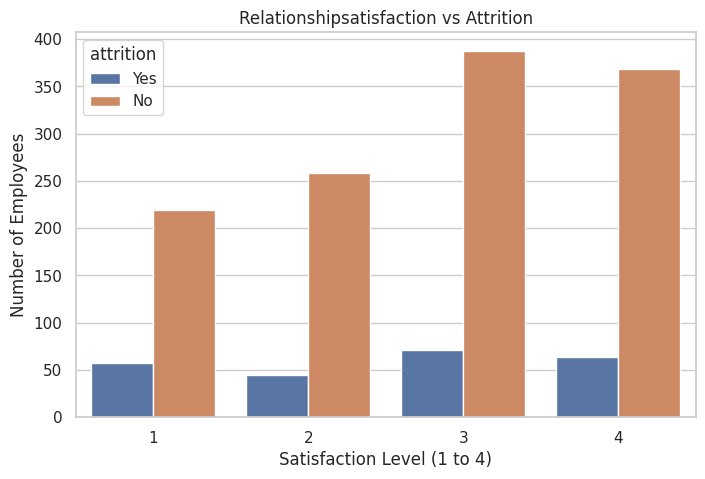

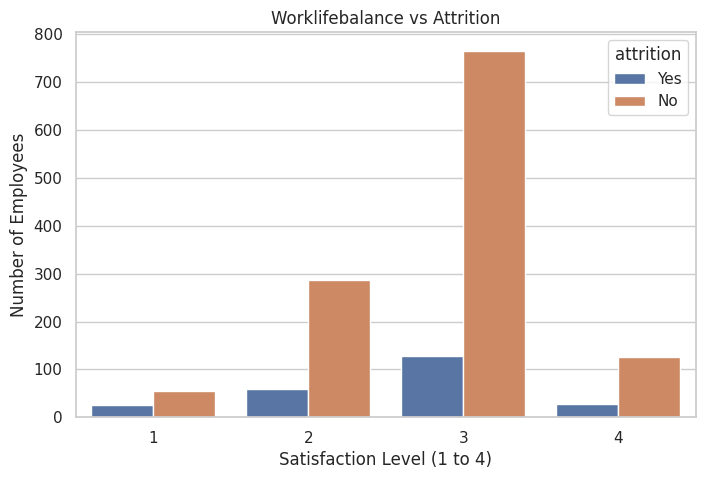

,jobsatisfaction,environmentsatisfaction,relationshipsatisfaction,worklifebalance
attrition,,,,
No,2.78,2.77,2.73,2.78
Yes,2.47,2.46,2.60,2.66


In [23]:

# Step 11: Analyze employee satisfaction

satisfaction_columns = [
    "jobsatisfaction",
    "environmentsatisfaction",
    "relationshipsatisfaction",
    "worklifebalance"
]

for col in satisfaction_columns:
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=cleaned_df,
        x=col,
        hue="attrition"
    )

    plt.title(f"{col.replace('_', ' ').title()} vs Attrition")
    plt.xlabel("Satisfaction Level (1 to 4)")
    plt.ylabel("Number of Employees")
    plt.show()

# Compare average satisfaction
display(
    cleaned_df.groupby("attrition")[satisfaction_columns].mean().round(2)
)


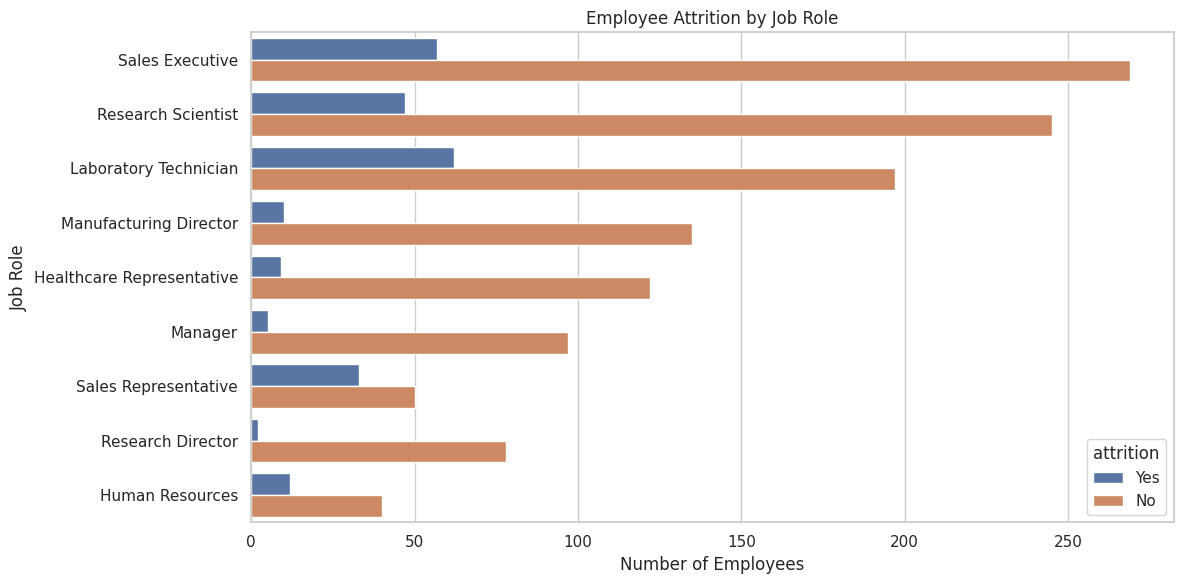

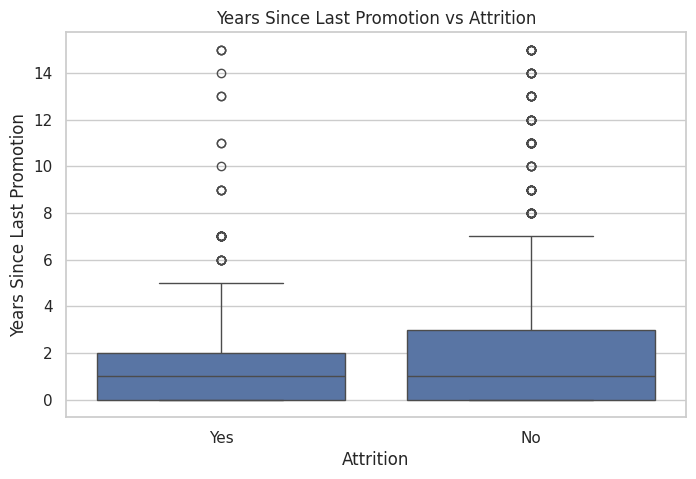

,count,mean,median
attrition,,,
No,1233,2.23,1.0
Yes,237,1.95,1.0


In [24]:

# Step 12A: Attrition by Job Role

plt.figure(figsize=(12, 6))

sns.countplot(
    data=cleaned_df,
    y="jobrole",
    hue="attrition"
)

plt.title("Employee Attrition by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

# Step 12B: Years Since Last Promotion

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=cleaned_df,
    x="attrition",
    y="yearssincelastpromotion"
)

plt.title("Years Since Last Promotion vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years Since Last Promotion")
plt.show()

# Summary table
display(
    cleaned_df.groupby("attrition")["yearssincelastpromotion"]
    .agg(["count", "mean", "median"])
    .round(2)
)


In [25]:

# Step 13: Feature Engineering

# 1. Group employees by years at company
cleaned_df["tenure_group"] = pd.cut(
    cleaned_df["yearsatcompany"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["0-2 years", "3-5 years", "6-10 years", "Above 10 years"]
)

# 2. Convert overtime into numeric values
cleaned_df["overtime_flag"] = (
    cleaned_df["overtime"]
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

# 3. Identify recent promotions
cleaned_df["promotion_recently"] = (
    cleaned_df["yearssincelastpromotion"] <= 2
).astype(int)

# Display the new columns
display(
    cleaned_df[
        [
            "yearsatcompany",
            "tenure_group",
            "overtime",
            "overtime_flag",
            "yearssincelastpromotion",
            "promotion_recently"
        ]
    ].head(10)
)

print("Step 13 completed successfully!")


,yearsatcompany,tenure_group,overtime,overtime_flag,yearssincelastpromotion,promotion_recently
0,6,6-10 years,Yes,1,0,1
1,10,6-10 years,No,0,1,1
2,0,0-2 years,Yes,1,0,1
3,8,6-10 years,Yes,1,3,0
4,2,0-2 years,No,0,2,1
5,7,6-10 years,No,0,3,0
6,1,0-2 years,Yes,1,0,1
7,1,0-2 years,No,0,0,1
8,9,6-10 years,No,0,1,1
9,7,6-10 years,No,0,7,0


Step 13 completed successfully!


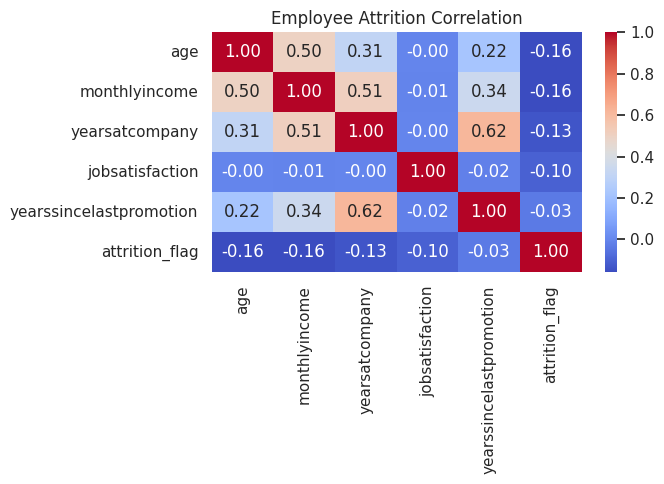

In [27]:

# Step 14A: Small Correlation Heatmap

important_columns = [
    "age",
    "monthlyincome",
    "yearsatcompany",
    "jobsatisfaction",
    "yearssincelastpromotion",
    "attrition_flag"
]

plt.figure(figsize=(7, 5))

sns.heatmap(
    cleaned_df[important_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Employee Attrition Correlation")
plt.tight_layout()
plt.show()


In [28]:

cleaned_df.to_csv("cleaned_employee_attrition.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [29]:

# Step 15: Create Excel Report

import pandas as pd
from google.colab import files

# Create analysis summary tables
department_analysis = pd.crosstab(
    cleaned_df["department"],
    cleaned_df["attrition"]
)

role_analysis = pd.crosstab(
    cleaned_df["jobrole"],
    cleaned_df["attrition"]
)

tenure_analysis = cleaned_df.groupby(
    "attrition"
)[
    ["yearsatcompany", "jobsatisfaction",
     "yearssincelastpromotion"]
].mean().round(2)

# Save all results in one Excel workbook
excel_file = "Employee_Attrition_Insight_Report.xlsx"

with pd.ExcelWriter(excel_file) as writer:
    cleaned_df.to_excel(
        writer, sheet_name="Cleaned_Data", index=False
    )
    department_analysis.to_excel(
        writer, sheet_name="Department_Analysis"
    )
    role_analysis.to_excel(
        writer, sheet_name="Job_Role_Analysis"
    )
    tenure_analysis.to_excel(
        writer, sheet_name="Attrition_Summary"
    )

print("Excel report created successfully!")

# Download Excel report
files.download(excel_file)


Excel report created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>